In [1]:
!pip install torchinfo

In [2]:
import random, numpy as np, torch
import torch
import torch.nn as nn
import torch.nn.functional as F
import nltk

seed = 42

# Python / NumPy
random.seed(seed)
np.random.seed(seed)

# Torch CPU/GPU
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

# CuDNN determinism
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
nltk.download('punkt')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.


True

# 1. Data preparation

In [4]:
from datasets import load_dataset

imdb = load_dataset("imdb")
train_data, test_data = imdb['train'], imdb['test']

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [5]:
# !pip -q install tokenizers

from tokenizers import Tokenizer
from tokenizers.models import WordLevel
from tokenizers.trainers import WordLevelTrainer
from tokenizers.pre_tokenizers import Whitespace
from tokenizers.normalizers import Lowercase

hf_tokenizer = Tokenizer(WordLevel(unk_token="<unk>"))
hf_tokenizer.normalizer = Lowercase()
hf_tokenizer.pre_tokenizer = Whitespace()

vocab_limit = 20000
min_freq = 3

trainer = WordLevelTrainer(
    vocab_size=vocab_limit,
    min_frequency=min_freq,
    special_tokens=["<pad>", "</s>", "<unk>"]
)

hf_tokenizer.train_from_iterator((x["text"] for x in train_data), trainer)

vocab = hf_tokenizer.get_vocab()
vocab_ordered = dict(sorted(vocab.items(), key=lambda x: x[1]))

PAD_ID = hf_tokenizer.token_to_id("<pad>")
EOS_ID = hf_tokenizer.token_to_id("</s>")
UNK_ID = hf_tokenizer.token_to_id("<unk>")

vocab_size = len(vocab_ordered)

print("HF vocab_size =", vocab_size)
print("SPECIAL:", {"<pad>": PAD_ID, "</s>": EOS_ID, "<unk>": UNK_ID})

HF vocab_size = 20000
SPECIAL: {'<pad>': 0, '</s>': 1, '<unk>': 2}


In [6]:
seq_length = 500

def text_pipeline(text: str):
    return hf_tokenizer.encode(text).ids

def collate_batch(batch, seq_length=seq_length):
    text_list, label_list = [], []
    for sample in batch:
        label_list.append(sample["label"])

        ids = text_pipeline(sample["text"])[:seq_length]

        if len(ids) < seq_length:
            pad_size = seq_length - len(ids) - 1
            ids = [PAD_ID] * pad_size + [EOS_ID] + ids

        text_list.append(ids)

    return (torch.tensor(text_list, dtype=torch.int64),
            torch.tensor(label_list, dtype=torch.int64))



In [7]:
from torch.utils.data import DataLoader
batch_size = 64

train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, collate_fn=collate_batch, drop_last=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, collate_fn=collate_batch, drop_last=True)

# 2. Model

In [8]:
class TextClsModel(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim, num_layers):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim)
        self.lstm = nn.LSTM(emb_dim, hidden_dim, num_layers = num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 2)

    def forward(self, x):
        x = self.embedding(x)
        output, (hidden, cell) = self.lstm(x)
        last_hidden = hidden[-1,:,:]
        x = self.fc(last_hidden)
        return x

In [9]:
model = TextClsModel(vocab_size=vocab_size,
                     emb_dim=128,
                     hidden_dim=64,
                     num_layers=2
                     )


In [10]:
from torchinfo import summary
summary(model, input_size=(64, seq_length), dtypes=[torch.long])

Layer (type:depth-idx)                   Output Shape              Param #
TextClsModel                             [64, 2]                   --
├─Embedding: 1-1                         [64, 500, 128]            2,560,000
├─LSTM: 1-2                              [64, 500, 64]             82,944
├─Linear: 1-3                            [64, 2]                   130
Total params: 2,643,074
Trainable params: 2,643,074
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 2.82
Input size (MB): 0.26
Forward/backward pass size (MB): 49.15
Params size (MB): 10.57
Estimated Total Size (MB): 59.98

# 3. Evaluate

In [ ]:
def evaluate(model, test_loader, criterion, device):
    model.eval()
    test_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            test_loss += loss.item()
            correct +=(predicted == labels).sum().item()

    test_loss = test_loss / len(test_loader)
    accuracy = 100* correct / total

    return test_loss, accuracy

# 4. Train

In [ ]:
device = 'cuda'
max_epoch = 20
LR = 0.01
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [ ]:
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []

model.to(device)
for epoch in range(max_epoch):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        running_correct += (predicted == labels).sum().item()

        loss.backward()
        optimizer.step()

    epoch_loss =  running_loss / len(train_loader)
    epoch_accuracy = 100* running_correct / total
    test_loss, test_accuracy = evaluate(model, test_loader, criterion, device)

    print(f"Epoch [{epoch + 1}/{max_epoch}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [1/20], Loss: 0.5177, Accuracy: 73.24%, Test Loss: 0.3878, Test Accuracy: 82.57%
Epoch [2/20], Loss: 0.2547, Accuracy: 89.96%, Test Loss: 0.3125, Test Accuracy: 87.22%
Epoch [3/20], Loss: 0.1477, Accuracy: 94.76%, Test Loss: 0.3569, Test Accuracy: 86.74%
Epoch [4/20], Loss: 0.0850, Accuracy: 97.14%, Test Loss: 0.3812, Test Accuracy: 86.63%
Epoch [5/20], Loss: 0.0601, Accuracy: 97.96%, Test Loss: 0.4057, Test Accuracy: 86.63%
Epoch [6/20], Loss: 0.0569, Accuracy: 98.02%, Test Loss: 0.4877, Test Accuracy: 87.01%
Epoch [7/20], Loss: 0.0454, Accuracy: 98.52%, Test Loss: 0.6155, Test Accuracy: 83.69%
Epoch [8/20], Loss: 0.0492, Accuracy: 98.32%, Test Loss: 0.5685, Test Accuracy: 85.73%
Epoch [9/20], Loss: 0.0364, Accuracy: 98.79%, Test Loss: 0.6010, Test Accuracy: 84.44%
Epoch [10/20], Loss: 0.0304, Accuracy: 98.95%, Test Loss: 0.5934, Test Accuracy: 85.56%
Epoch [11/20], Loss: 0.0322, Accuracy: 98.90%, Test Loss: 0.5865, Test Accuracy: 85.99%
Epoch [12/20], Loss: 0.0246, Accuracy: 99

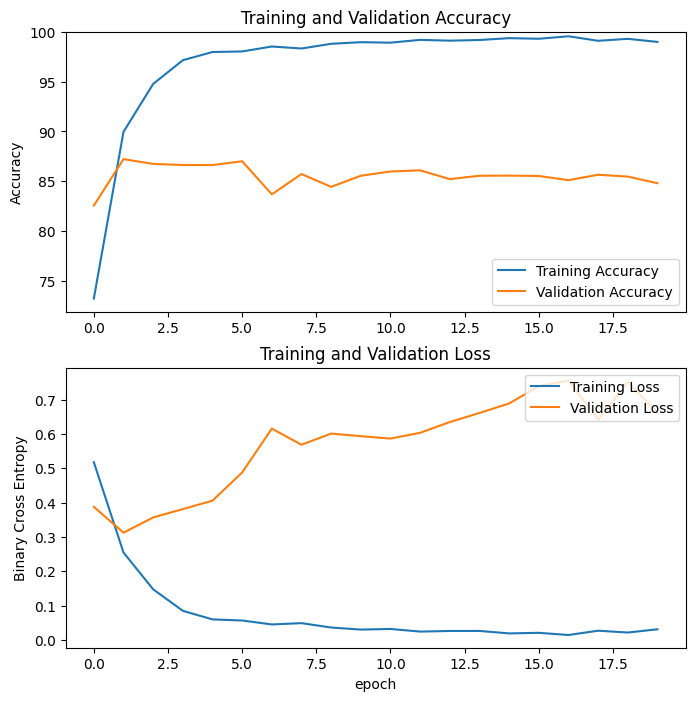

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(train_accuracies, label='Training Accuracy')
plt.plot(test_accuracies, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),100])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(train_losses, label='Training Loss')
plt.plot(test_losses, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Binary Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()